# Data Description of YouNiverse

In [1]:
# Imports
from scipy.stats import mannwhitneyu

from src.data.loader import load_raw_datasets, iterate_parquet_stream, iterate_videos_light_stream
from src.data.preprocessing import apply_data_processing
from src.data.quality_check import check_data_quality_on_datasets
from src.models.log_log_efficiency_model import linear_log_log_model
from src.models.spec_model import run_spec_small_mid
from src.utils.general_utils import weighted_percentiles
from src.models.propensity_matching import estimate_propensity_scores, match_nearest_neighbor_within_category
from src.utils.data_utils import calculate_stagnation_rate, add_structural_factors, split_channels_by_subscriber_tier_weighted
from src.utils.general_utils import weighted_percentiles, perform_mannwhitney_test, calculate_smd, check_growth_milestones
from config import *
from src.utils.plots import *

# Style
sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6 # for reproducing the results

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

### Note

This notebook contains our milestone 2 results (up to part 1.3: [Data Analysis on All Dataset](#III.-Data-Analysis-On-All-Dataset))

Milestone 3 results start at part 1.4: [Making the decline detection better](#iv-making-the-decline-detection-better).

As this notebook contains all of our work, running it as is will take a very long time. That is why we often load the data, as it allows to run some specific parts more quickly.

## Table of Contents

- [1. Data Exploration](#1-data-exploration)
  - [1.1 Loading Raw Data](#11-loading-raw-data)
  - [1.2 Checking data quality](#12-checking-data-quality)
  - [1.3 Correlation matrix](#13-correlation-matrix)
  - [1.4 Decisions on Data Preprocessing](#14-decisions-on-data-preprocessing)
    - [Cleaning & Storage](#cleaning--storage)
    - [Feature Engineering](#feature-engineering)
- [2. Loading the data](#2-loading-the-data)
  - [2.1 Run the preprocessing pipeline](#21-run-the-preprocessing-pipeline)
  - [2.2 Checking the processed data](#22-checking-the-processed-data)
- [3. Basic information about the data](#3-basic-information-about-the-data)
  - [3.1 Subscribers distribution](#31-subscribers-distribution)
  - [3.2 Average Efficiency by category](#32-average-efficiency-by-category)
  - [3.3 Efficiency overtime](#33-efficiency-overtime)
- [4. Detecting Outperformers – Research Question 1](#4-detecting-outperformers---research-queston-1)
  - [4.1 Identifying small to mid sized channels](#41-identifying-small-to-mid-sized-channels)
  - [4.2 Fitting the Model and Detecting the Outperformers](#42-fitting-the-model-and-detecting-the-outperformers)
    - [4.3 Categories of quiet outperformers](#43-categories-of-quiet-outperformers)
    - [4.4 Diving into one Outperformer](#44-diving-into-one-outperformer)
- [5. Categories of Outperformers - Research Question 2](#5-categories-of-outperformers---research-question-2)
- [6. Structural Factors - Research Question 3](#6-structural-factors---research-question-3)
- [7. Growth Analysis - Research Question 4](#7-growth-analysis---research-question-4)
  - [7.1 Metric 1: Historical Mean Weekly Subscriber Gain](#71-metric-1-historical-mean-weekly-subscriber-gain)
  - [7.2 Metric 1A: Unadjusted Descriptive Growth](#72-metric-1a-unadjusted-descriptive-growth)
  - [7.3 Propensity Score Matching (PSM)](#73-propensity-score-matching-psm)
  - [7.4 Metric 1B and 2: Matched Performance (Subscribers and Views)](#74-metric-1b-and-2-matched-performance-subscribers-and-views)
  - [7.5 Metric 3 - Stability & Activity Context (Metrics 3A & 3B)](#75-metric-3---stability--activity-context-metrics-3a--3b)
  - [7.6 Metric 4: Long-Term Cumulative Growth Trajectory](#76-metric-4-long-term-cumulative-growth-trajectory)
  - [7.7 Final Conclusion: The Anatomy of a "Quiet Outperformer"](#77-final-conclusion-the-anatomy-of-a-quiet-outperformer)


## 1 Data Exploration


Our Project will need data from these datasets:
- `df_channels_en.tsv.gz`: Channel data.
- `df_timeseries_en.tsv.gz` : Channel data over time including `delta views`, `delta_videos` and `delta_subs`.
- `yt_metadata_en.jsonl.gz` : Metadata for each video
- `num_comments.tsv.gz` : Number of comments per video.
- `yt_metadata_helper.feather` : A lighter version of video metadata not including description, titles and tags.

Before proceeding please make sure these datasets are located in the `data/raw` folder.

To get a better feel for the datasets, we begin by inspecting each of the datasets.
Our goal in this section is to understand structure, size and feasibility of working with the raw data.

### 1.1 Loading Raw Data

Due to hardware constraints, we initially analyzed the first one million rows of each dataset to understand data structure and variable relationships.

In [ ]:
subset_size = 1_000_000
channels_df, videos_df, videos_light_df, timeseries_df, num_comments_df = load_raw_datasets(all=True, nrows=subset_size)

### 1.2 Checking data quality

Before deciding on pre-processing the data, it is important to take a look at the quality metrics.

In [3]:
df_list = [channels_df,
           videos_df,
           videos_light_df,
           timeseries_df,
           num_comments_df]

names = ["Channels", "Videos", "Videos (Light)", "Timeseries", "Num Comments"]

check_data_quality_on_datasets(df_list, names)

,Dataset,Rows,Columns,Missing %,Duplicate %,Memory (MB),Numeric Cols,Categorical Cols,Non-Null % (avg),Unique % (avg),Min Numeric,Max Numeric
1,Videos,1000000,8,0.49,0.0,222.04,4,4,99.51,15.34,0.0000,1.101396e+09
3,Timeseries,1000000,10,0.01,0.0,244.81,7,3,99.99,32.20,0.0000,1.334730e+10
2,Videos (Light),1000000,12,0.33,0.0,2382.38,4,8,99.67,38.61,0.0000,1.101396e+09
4,Num Comments,1000000,2,0.00,0.0,64.85,1,1,100.00,50.40,0.0000,2.231960e+05
0,Channels,136470,8,0.01,0.0,37.25,4,4,99.99,42.90,2.0865,1.121395e+08


The quick quality report tells us there are not a lot of missing values. However, we should be aware of that and preprocess the data.

### 1.3 Correlation matrix

Because `videos_df` and `videos_light_df` share the same numerical columns, we avoided loading the large `videos_df `file—which does not fit into memory—and computed the correlation matrix using the lighter dataset instead.

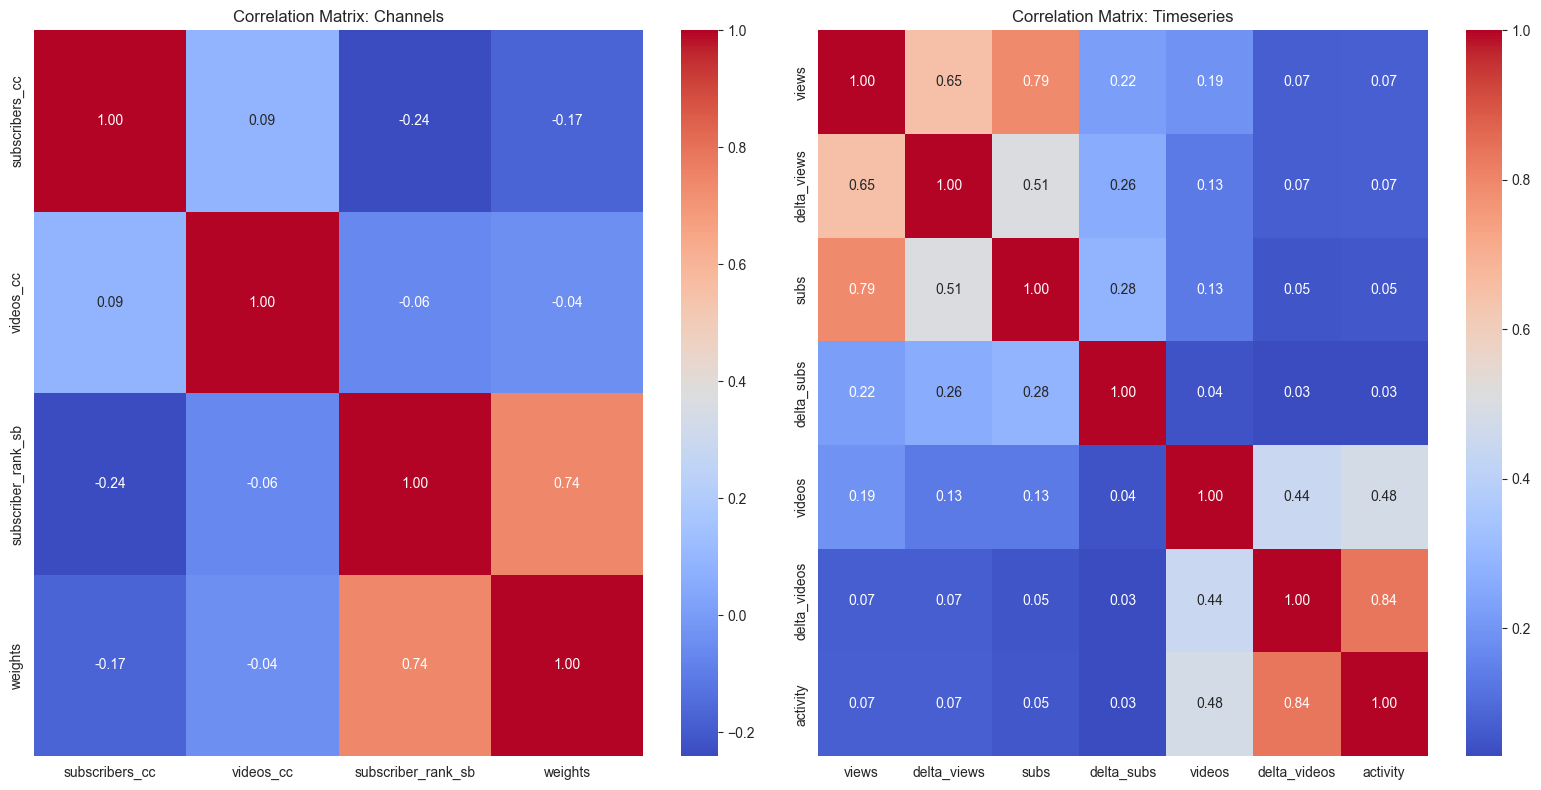

In [2]:
# Reloading with all rows
channels_df, _, _, timeseries_df, _ = load_raw_datasets(load_only=["channels", "timeseries"])

# Adding names
corr_df_list = [channels_df, timeseries_df]
corr_names=["Channels", "Timeseries"]

fig = plot_correlation_matrices(corr_df_list, corr_names, figsize=(16, 8))
plt.show()


As `videos_light` cannot be loaded entirely into memory, correlations are computed incrementally by streaming row chunks through a callable interface, decoupling the computation from the data source.

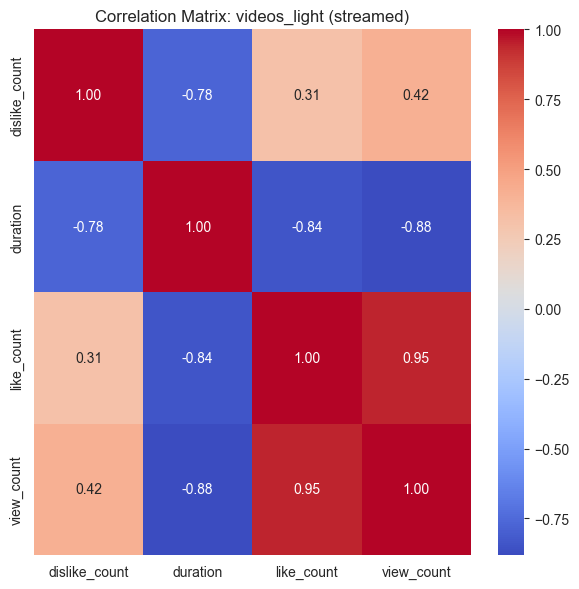

In [14]:
fig = plot_streamed_correlation(
    stream_fn=iterate_videos_light_stream,
    path=RAW_DATASET_VIDEO_METADATA_LIGHT,
    nrows=None,          
    stream_kwargs={"window_size": 20_000_000},
    title="Correlation Matrix: videos_light (streamed)",
    figsize=(6,6)
)

plt.show()

First glance insights:
- Channel-level correlations are weak, more uploads don’t clearly relate to more subscribers or better ranks.
- Video-level metrics (views, likes, dislikes) are tightly linked, while duration shows no clear impact on engagement.
- In time-series data, views and subscribers grow together but with only moderate alignment in their weekly changes.

 We note that this subset was not randomly sampled, so correlations are preliminary and may not reflect the global population.

### 1.4 Decisions on Data Preprocessing

Because the dataset is large, we process the data and save the results in Parquet format.
This format allows for faster access and supports iterative reading, which solves the issue of not being able to load everything into memory at once.
The following steps are taken in align with the project goals, code is located in `src/data/preprocessing.py`

#### Cleaning & Storage
We perform standard cleaning for each dataset — removing duplicates, normalizing types and formats, and parsing dates.

Additionally, we created a new lightweight dataset `tags_processed.parquet`, containing only `channel_id`, `display_id`(video_id), `tags`, and `upload_date`.
This dataset will be used later in Research Question 2 to cluster different YouTube categories, and was separated to allow faster processing without reloading the large video metadata file.


##### Feature Engineering
Feature engineering is a key part of our pipeline, as these variables are later reused across multiple analyses.
Bellow are some of the most important ones:

- **Engagement Efficiency (video level)**
  For each video *v*:
  $$
  E_v = \frac{\text{likes}_v + \text{dislikes}_v + \text{comments}_v}{\text{views}_v}
  $$
  This score is used for detecting outperformers, and since it is reused a lot, we decided to include it in our saved processed datasets.

<br>

In `time_series.data`, <br>
we align all events to weekly periods (W-MON) and aggregate per channel:
- `lifetime_reactions_week = Σ(likes + dislikes + comments)` — sum of lifetime reactions for all videos uploaded in that week
- `lifetime_views_week = Σ(views)` — sum of lifetime views for all videos uploaded in that week

Due to the dataset limitations, the engagement metrics (likes, dislikes, comments) in the dataset are snapshot values recorded at crawl time (Oct–Nov 2019), not true time series. Therefore, these weekly aggregates represent the **lifetime engagement totals** of videos uploaded in each week, rather than engagement accumulated during that week. This interpretation is still valuable for analyzing recent creative output and topic shifts over time (supports RQ3).

We then compute:
- **Weekly Efficiency**
$$
E_{\text{week}} = \frac{\text{lifetime\_reactions\_week}}{\text{lifetime\_views\_week}}
$$
- **4-Week Trailing Efficiency**
  A rolling version for smoother trends in the `timeseries` dataset.


- **Channel Aggregates (from processed videos)**
  - `avg_engagement_efficiency` — mean efficiency across all channel videos
  - `total_views`, `total_like_count`, `total_dislike_count`, `total_num_comms` — cumulative metrics
  - `avg_video_like_ratio`, `video_count_processed` — engagement and volume indicators
  - `channel_age_days`, `videos_per_day` — activity and lifespan measures

All processed datasets are saved under `/data/processed/` for efficient downstream use.

## 2 Loading the data


### 2.1 Run the preprocessing pipeline

By running the preprocessing pipeline, it takes each dataset from the `data/raw` folder, preprocesses them and saves them in `data/processed` for later use. Before running the function, please make sure you have the python libraries in `requirements.txt` installed, and you have the original datasets in the `raw` folder.

Depending on the machine, this process can take from 30 minutes to a couple of hours.


In [15]:
apply_data_processing()

STEP 1: Processing num_comments
++ Saved processed num_comments to /home/joao/Documents/EPFL/Year1-25-26/Semester1/AppliedDataAnalysis/ada-2025-project-in5ight/data/processed/num_comments_processed.parquet
  Shape: (72924794, 2)

STEP 3: Processing video_light (feather)
Processing video_light in chunks of 20 million rows...
Total record batches in file: 1,113
Processing in chunks...

Processing chunk 1 (20,054,016 rows)...
  ++ Chunk 1 processed: 20,054,016 rows
Processing chunk 2 (20,054,016 rows)...
  ++ Chunk 2 processed: 20,054,016 rows
Processing chunk 3 (20,054,016 rows)...
  ++ Chunk 3 processed: 20,054,016 rows
Processing chunk 4 (12,762,746 rows)...
  ++ Chunk 4 processed: 12,762,746 rows

++ Saved processed video_light to /home/joao/Documents/EPFL/Year1-25-26/Semester1/AppliedDataAnalysis/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet
  Total rows processed: 72,924,794

STEP 4: Loading existing channels (already processed)
  Shape: (136470, 18)

STEP 5

### 2.2 Checking the processed data

In [5]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(6)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.861188,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.939069,40549
5,Entertainment,2007-01-15,UCIwFjwMjI0y7PDBVEO9-bkQ,Justin Bieber,46574085,134,12.0,2.087,4668.0,0.028706,0.025269,5.886436e+08,17697.0,8815774.0,373636.0,719646.0,0.957442,128


In [6]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled,posting_pace_4w,posting_consistency_4w,posting_pace_8w,posting_consistency_8w,posting_pace_12w,posting_consistency_12w
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,2016-07-26,0.049820,0.049820,0.0,0.000000,0.0,0.000000,0.0,0.000000
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,2016-08-02,0.049374,0.049374,0.0,1.000000,0.0,1.000000,0.0,1.000000
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,2016-08-09,0.045413,0.045413,0.0,0.000000,0.0,0.000000,0.0,0.000000
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,2016-08-16,0.046415,0.046415,1.0,0.000000,1.0,0.000000,1.0,0.000000
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,2016-08-23,0.031169,0.031169,1.0,0.333333,1.0,0.087129,1.0,0.087129


Datasets that are too large to fit in memory at once like `videos_metadata_processed.parquet`, `videos_light_processed.parquet` and `tags_processed.parquet`, we process iteratively, meaning, we read it by chunks. This ensures that we can use these datasets in our Research Questions and proves feasibility.

_The larger 20GB `videos_metadata_processed.parquet` takes around 30 minutes in our local machines._


In [23]:
# Example of reading from videos_light_processed.parquet with chunks
for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=20_000_000):
    print(df_chunk.shape)

(20054016, 11)
++ Chunk 000: rows 0-20,054,016 | total=20,054,016
(20054016, 11)
++ Chunk 001: rows 20,054,016-40,108,032 | total=40,108,032
(20054016, 11)
++ Chunk 002: rows 40,108,032-60,162,048 | total=60,162,048
(12762746, 11)
++ Final chunk: rows 60,162,048-EOF | rows=12,762,746


# 3 Basic information about the data

### 3.1 Subscribers distribution

As our research is focused on working with small- to midsize-channels, it is important to understand overall image of subscribers count.

In [4]:
# Compute weighted 50th (median) and 90th percentiles of subscriber counts
channel_df =  pd.read_parquet(DATASET_CHANNELS)
cuts = weighted_percentiles(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    percentiles=(50, 90)
)
print(cuts)
p50, p90 = cuts[50], cuts[90]

{50: np.float64(22200.0), 90: np.float64(160000.0)}


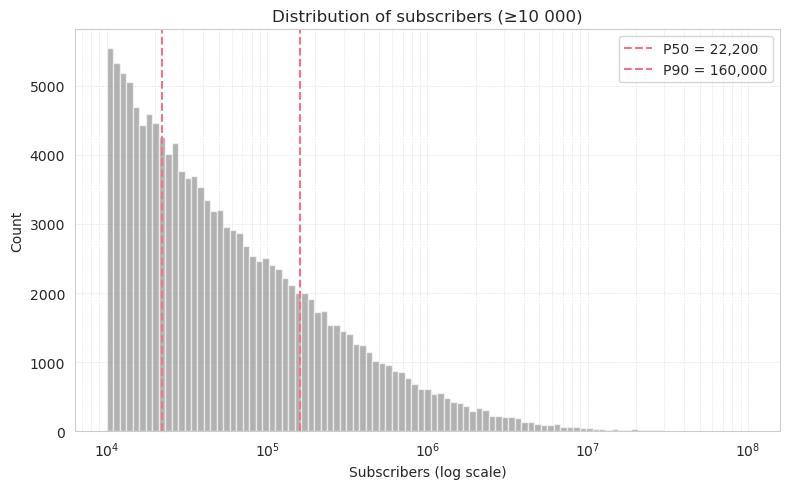

In [5]:
plot_log_histogram(
    channel_df,
    column_name="subscribers_cc",
    percentile_markers={"P50": p50, "P90": p90},
    bins=np.logspace(4, 8, 100),
    plot_title="Distribution of subscribers (≥10 000)",
    x_axis_label="Subscribers (log scale)"
)
plt.show()

The distribution is highly right-skewed (heavy-tailed), most channels cluster near the lower end (10 k – 100 k), and very few extend into the millions.

### 3.2 Average Efficiency by category

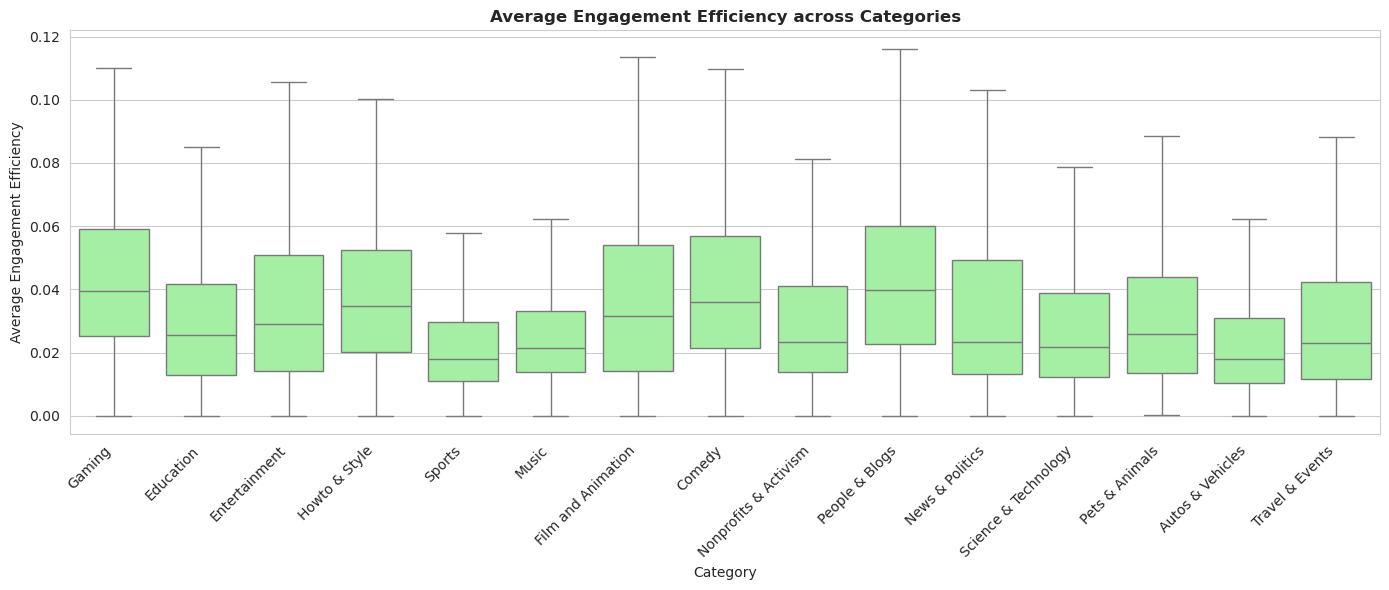

In [6]:
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=channel_df,
    x="category_cc",
    y="avg_engagement_efficiency",
    color="palegreen",
    showfliers=False
)
plt.title("Average Engagement Efficiency across Categories", weight="bold")
plt.xlabel("Category")
plt.ylabel("Average Engagement Efficiency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

This indicates that content type strongly influences how actively viewers engage with creators.

### 3.3 Efficiency overtime

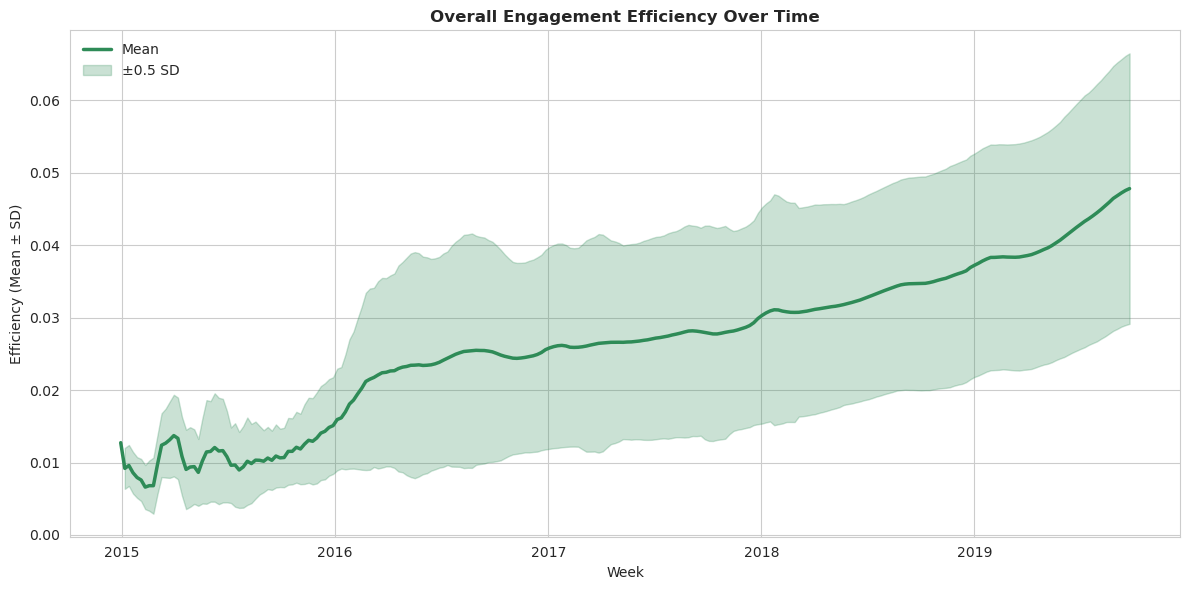

In [7]:
plot_timeseries_trend(
    df=timeseries_df,
    date_col="week_start",
    value_col="efficiency_4week_filled",
    title="Overall Engagement Efficiency Over Time",
    xlabel="Week",
    ylabel="Efficiency (Mean ± SD)",
    smooth=True,
    window=6,
    color="seagreen"
)

The time series shows a clear upward trend in overall engagement efficiency from 2015 to 2019.
This indicates that over time, viewers have become increasingly active in leaving likes, dislikes, and comments relative to the number of views.

# 4 Detecting Outperformers - Research Queston 1

### 4.1 Identifying small to mid sized channels

We define our focus cohort as channels with 10 000–100 000 subscribers. The subscriber distribution is heavy-tailed: the median (P50) is ≈ 22 k and P90 is ≈ 160 k, so 100 k lies well below the top decile while meaningfully above the median. We use 100 k because it:
- aligns with YouTube’s Silver Creator milestone,
- avoids dominance by a small set of very large channels and
 - provides a large, comparable sample of growing creators.

In [8]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### 4.2 Fitting the Model and Detecting the Outperformers

Outperformers are defined as small- to mid-sized channels that achieve an engagement efficiency substantially higher than what is expected for their subscriber size and category, after controlling for the heavy-tailed scaling of engagement on YouTube.

Starting from the efficiency metric that we defined in feature engineering, we continue with:

- **Expected Efficiency Model (Log–Log Linear Regression)**

  To understand how efficiency scales with channel size, we fit a log–log regression:
  $$
  \log_{10}(E_c) = a + b \, \log_{10}(\text{subscribers}_c) + \varepsilon_c
  $$
  Using logs stabilizes the heavy-tailed data and makes the relationship approximately linear.
  This model captures the power-law scaling between engagement and audience size, allowing us to identify channels whose efficiency significantly exceeds the expected baseline for their size.

- **Residual Efficiency (Deviation from Expectation)**

  The residual measures how much a channel over- or under-performs relative to its expected efficiency:
  $$
  r_c = \log_{10}(E_c) - \big(a + b \, \log_{10}(\text{subscribers}_c)\big)
  $$

- **Quiet Outperformers**

  Channels with residuals above a threshold \( \gamma \) (e.g., mean + 2·std or the top 5%) are labeled as outperformers:
  $$
  r_c > \gamma \;\Rightarrow\; \text{quiet outperformer}
  $$

In [9]:
channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,174949.0,2266.0,29914.0,0.986781,16,4.992111,-1.164280,-1.613989,0.449709,1.233636
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,216481.0,19153.0,13512.0,0.978910,267,4.965202,-1.488122,-1.610172,0.122050,0.341271
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,199670.0,5360.0,8565.0,0.965106,35,4.994242,-1.531054,-1.614292,0.083238,0.235570
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,299536.0,13301.0,12879.0,0.970602,52,4.992120,-1.529482,-1.613991,0.084508,0.239030
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,232189.0,17840.0,2423.0,0.899380,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900


The residual distribution is approximately bell-shaped but slightly right-skewed, reflecting that most channels perform near their expected efficiency while a small subset achieve substantially higher engagement relative to size.
We define outperformers as those above the 97th percentile, representing the top 3% of channels with the largest positive deviations.
This stricter cutoff filters out statistical noise and highlights genuinely exceptional channels whose audience engagement is consistently beyond what their subscriber base would predict.

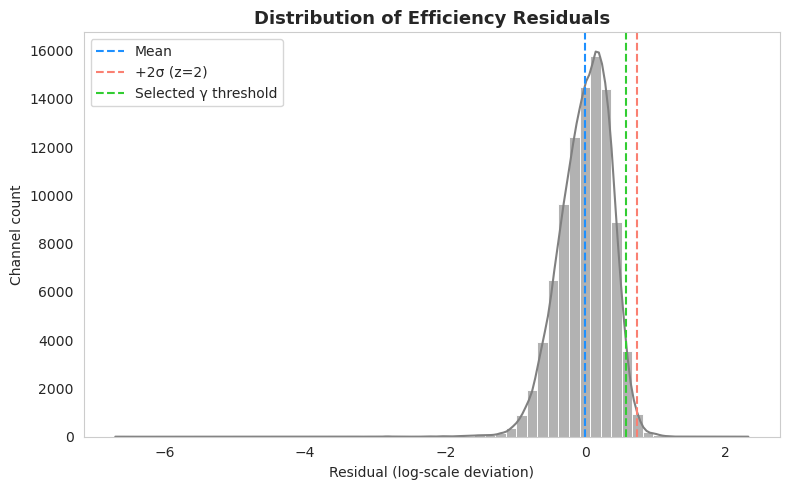

In [10]:
gamma = np.percentile(channels_model["residual"], 97)
plot_residual_distribution(channels_model["residual"], threshold_gamma=gamma)

In [11]:
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)

In [12]:
outperformers_df = channel_df[channel_df['is_outperformer']]
non_outperformers_df = channel_df[~channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,0.996371,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,0.968095,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,0.979401,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,0.995255,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,0.977471,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,0.864303,55,True


#### 4.3 Categories of quiet outperformers

Initially, dataset provides us a correspondence of each channel to 1 of 15 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data. We explore this on Research Question 2._

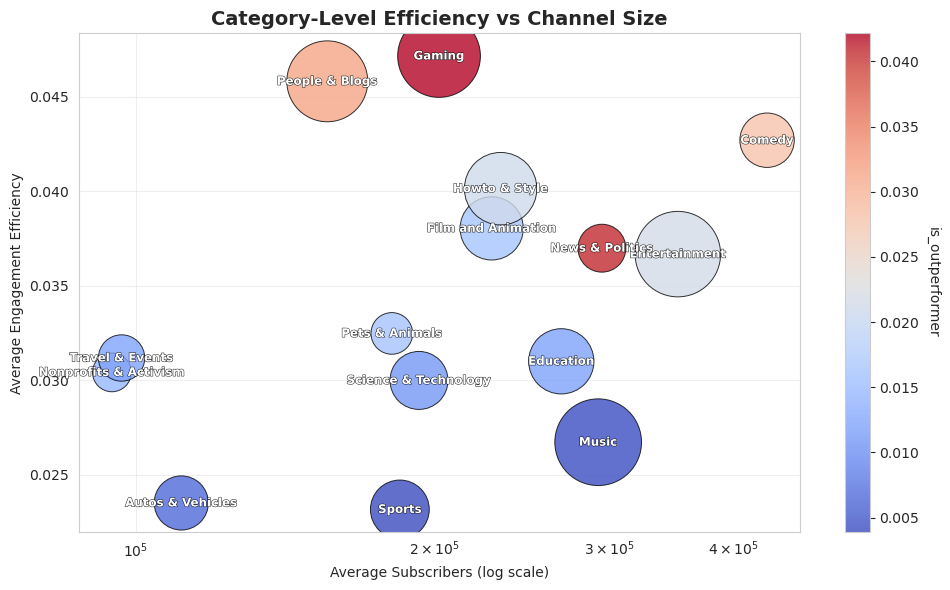

In [13]:
plot_category_bubble(
    dataframe=channel_df,
    size_column="subscribers_cc",
    value_column="avg_engagement_efficiency",
    category_column="category_cc",
    color_column="is_outperformer",  # average will give share of outperformers
    plot_title="Category-Level Efficiency vs Channel Size",
    x_axis_label="Average Subscribers (log scale)",
    y_axis_label="Average Engagement Efficiency",
)

#### 4.4 Diving into one Outperformer

Let’s take a closer look at one of the top quiet outperformers, the channel “Gym Monk / Gaming.”
This channel still exists today with around 28K subscribers, and during the 2019 period it had multiple videos reaching hundreds of thousands of views.

In [14]:
# Loading the time series data
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)

In [15]:
channel = 'UCfs20O_RuLJXGGTxv5VIzdw'
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]
channel_timeseries.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
12899150,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-04-25,26360.750,63.750,1775.750,0.000,77,0,11,2016-04-19,1.208036,1.208036
12899151,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-02,26807.000,446.250,1795.000,19.250,77,0,6,2016-04-26,NaN,NaN
12899152,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-09,27071.250,264.250,1806.375,11.375,78,1,1,2016-05-03,1.193830,1.193830
12899153,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-16,27407.500,336.250,1814.750,8.375,80,2,3,2016-05-10,1.154780,1.154780
12899154,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-23,28045.125,637.625,1830.125,15.375,84,4,6,2016-05-17,0.880374,0.880374


Let's compare his efficiency(outperformer) to someone who is in the same category "Gaming" and has an average efficiency.


In [16]:
target_channel = "UCfs20O_RuLJXGGTxv5VIzdw"
target_eff = channel_df.loc[channel_df["channel"] == target_channel, "avg_engagement_efficiency"].iloc[0]

# Find average efficiency for Gaming category
avg_eff_gaming = (
    channel_df.loc[channel_df["category_cc"] == "Gaming", "avg_engagement_efficiency"]
    .mean()
)

# Find channel in Gaming closest to that average
avg_channel = (
    channel_df[channel_df["category_cc"] == "Gaming"]
    .assign(diff=lambda x: (x["avg_engagement_efficiency"] - avg_eff_gaming).abs())
    .sort_values("diff")
    .iloc[0]
)

avg_channel_id = avg_channel["channel"]
avg_channel_eff = avg_channel["avg_engagement_efficiency"]

print(f"Matched 'average' Gaming channel: {avg_channel_id}")

Matched 'average' Gaming channel: UCRZ5-H-PV_2jsj3JsB9uU2A


In [17]:
channel_2 = 'UCRZ5-H-PV_2jsj3JsB9uU2A'
channel_timeseries_2 = timeseries_df[timeseries_df['channel'] == channel_2]
channel_timeseries_2.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
8395116,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-02,178813.500,751.500,831.000,0.000,5,0,0,2016-04-26,NaN,NaN
8395117,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-09,180609.500,1796.000,837.750,6.750,5,0,0,2016-05-03,NaN,NaN
8395118,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-16,182562.375,1952.875,845.125,7.375,6,1,1,2016-05-10,0.012577,0.012577
8395119,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-23,184819.000,2256.625,860.000,14.875,7,1,2,2016-05-17,0.010054,0.010054
8395120,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-30,186508.625,1689.625,867.000,7.000,8,1,2,2016-05-24,0.015791,0.015791


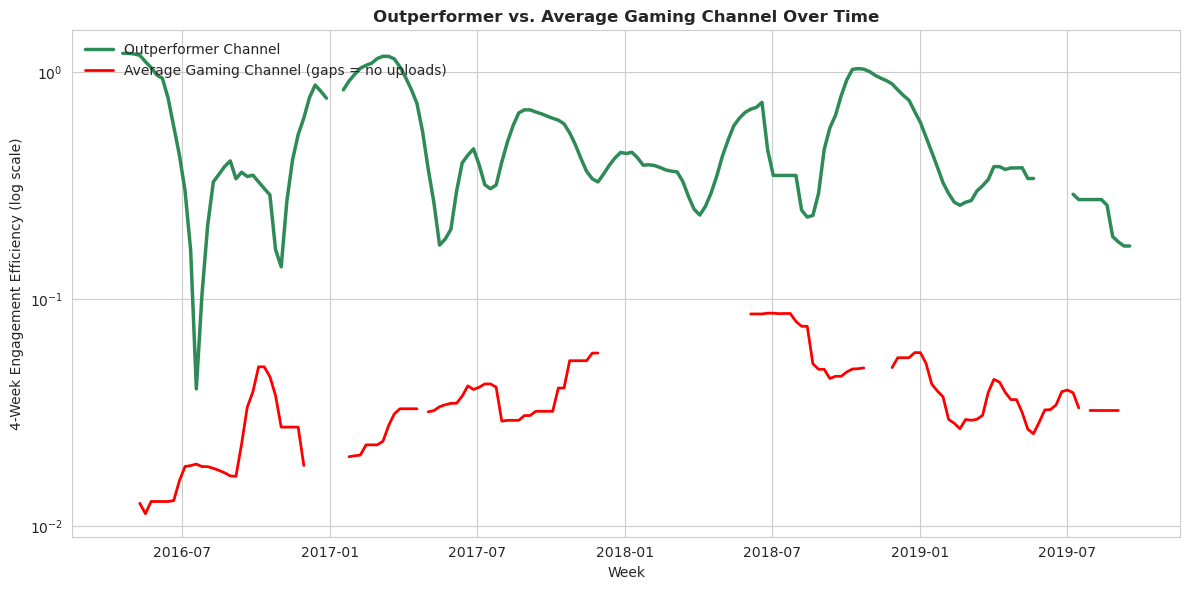

In [18]:
plot_channel_comparison(
    df=timeseries_df,
    target_channel=target_channel,
    avg_channel_id=avg_channel_id,
)

As expected, the outperformer channel achieves consistently higher engagement efficiency than the average Gaming channel throughout the observed period.
Additionally, the outperformer shows fewer and shorter inactivity gaps, indicating a more consistent upload pattern and sustained audience engagement over time.


These observations motivate our subsequent research questions. Having established that a quiet outperformer achieves consistently higher engagement efficiency and more stable activity than a comparable average Gaming channel, we next ask whether this pattern generalizes across the platform. Specifically, we investigate how quiet outperformers are distributed across content communities (RQ2), which structural or strategic choices, such as posting frequency, duration, or timing, are statistically associated with higher efficiency within each size tier and content type (RQ3), and finally, whether quiet outperformers sustain more stable growth in views and subscribers compared to similar non-outperforming channels (RQ4). Together, these questions aim to uncover the structural and behavioral factors that differentiate quiet outperformers from typical creators beyond raw engagement metrics.

# 5 Categories of Outperformers - Research Question 2

# 6 Structural Factors - Research Question 3

We analyze how structural choices relate to engagement efficiency while removing scale effects and comparing channels within size tiers. Because efficiency co-varies with subscriber count and channels differ by composition, naive comparisons are biased. We address this by residualizing efficiency against size in a log–log baseline, and estimating within-tier regressions.



**Structural Predictors (8-week window)**

All predictors are backward-looking and summarized at the channel level:

- Posting frequency (pace): median weekly uploads over the prior 8 weeks.
- Posting consistency (0–1):
$$
\text{cons8} \;=\; \mathrm{clip}\!\left(1-\frac{\mathrm{std}_8}{\max(\mathrm{mean}_8,\varepsilon)},\,0,\,1\right),\quad \varepsilon=0.1.
$$
- Video duration: channel median duration; modeled as $\log(\text{duration})$ to reduce skew.



**Size Tiers**

Tiers are defined by subscriber quantiles:
- Small: 0–50th percentile
- Mid: over 50th percentile with upper bound at 100,000

Analyses are run separately within each tier.


In [18]:
# Refit Log-Log Model on Full Channel Cohort to obtain final residuals
channels_model = linear_log_log_model(
    df=channel_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

log–log model fitted: log(y) = -1.0105 + -0.1174 * log(x)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927,8.004321,-1.376875,-1.949860,0.572984,1.573593
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462,7.778874,-2.529615,-1.923402,-0.606213,-1.651979
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.861188,23903,7.748334,-2.301560,-1.919818,-0.381742,-1.037961
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624,7.782473,-1.945371,-1.923824,-0.021547,-0.052685
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.939069,40549,7.684845,-1.800178,-1.912367,0.112188,0.313134


In [19]:
# Aggregate (median) Structural Factors from Timeseries (pace, consistency) and Videos (duration) per Channel
channels_model = add_structural_factors(channels_model, timeseries_df, videos_dataset=DATASET_VIDEO_LIGHT)

# split into Small and Mid-Sized Channel as defined befor
small_df, mid_df = split_channels_by_subscriber_tier_weighted(channels_model)

To first see how structural factors relate to efficiency, we plotted heatmaps over pairs of structural features (pace, consistency, and duration) within small and mid tiers. Each cell shows the median efficiency residual for channels that fall into that combination of bins, letting us quickly spot non linear patterns and interaction like behavior that would be hard to see from one variable at a time.

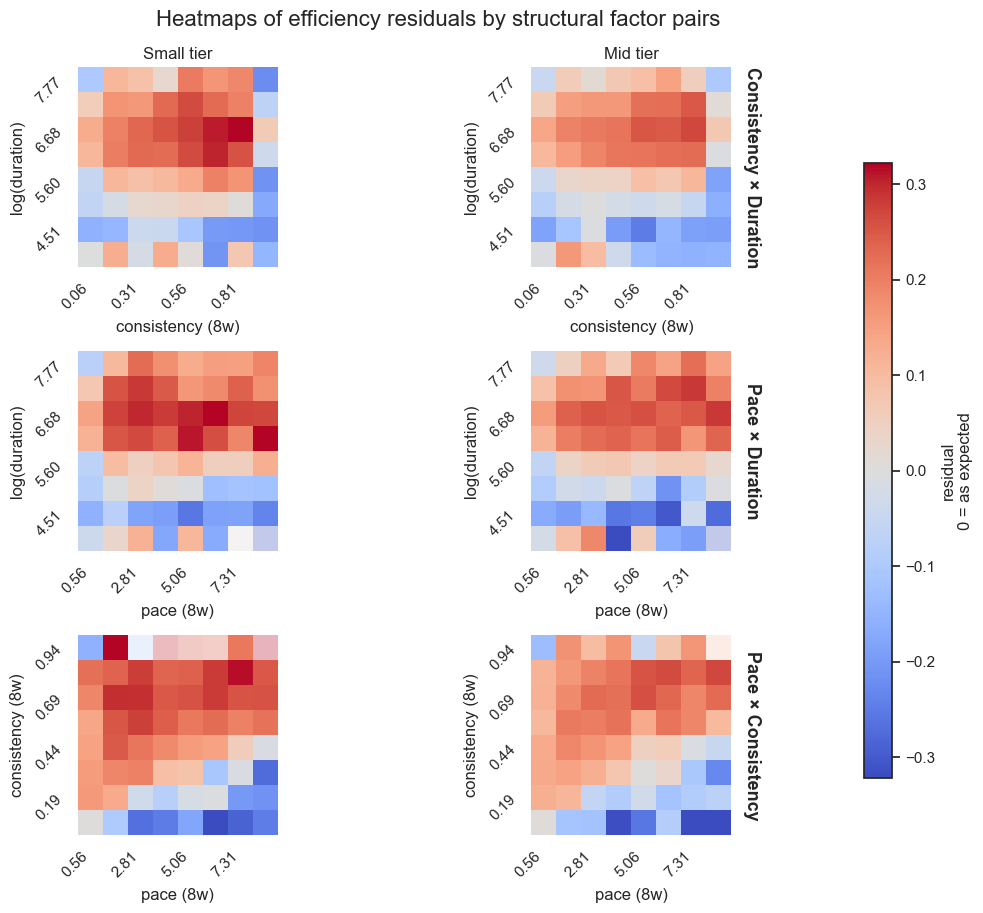

In [20]:
plot_recipe_maps_3x2(small_df, mid_df, bins=8, min_cell_n=8, low_opacity=0.30)

From these heatmaps, the strongest and most consistent pattern is that higher efficiency tends to concentrate at moderate to high log(duration) around 6 to 7.5 for both tiers, while very short durations around 4 to 5 are generally associated with underperformance. In the pace-consistency map, the clearest "bad" region is high pace combined with low consistency, which is strongly negative, whereas higher consistency is broadly associated with better outcomes even when pace is moderate to high. Overall the structure is similar in small and mid, with small showing slightly sharper extremes.

### 6.1 Collinearity analysis between pace, consistency and duration


Before fitting the within tier WLS models, we want these structural predictors (pace, consistency, and log(duration)) to be reasonably independent of each other. If they were strongly related, the model could struggle to separate their individual contributions, making coefficient estimates unstable and harder to interpret when we compare effects across tiers.

We check this with two diagnostics:

- Absolute pairwise correlations within each tier

- VIF (Variance Inflation Factor), which measures multicollinearity in a regression style way

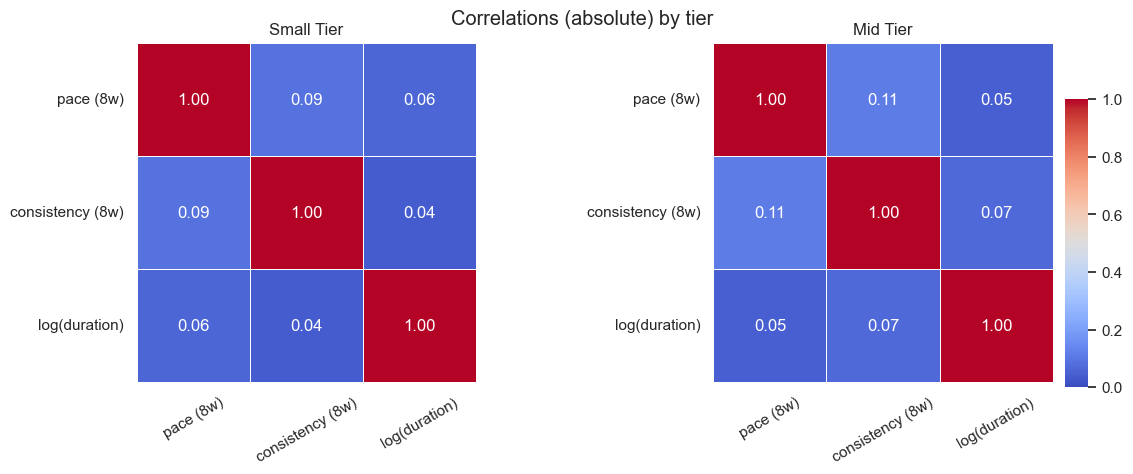

In [21]:
# Correlation Matrices for Small and Mid-Sized Channels
plot_corr_small_mid(
    small_df, mid_df,
    pace_col="pace8_median",
    cons_col="cons8_median",
)


In [22]:
# VIF Calculation for Small and Mid-Sized Channels
vif_df = vif_table_small_mid(
    small_df, mid_df,
    pace_col="pace8_median",
    cons_col="cons8_median",
)

display(
    vif_df.style
        .format("{:.2f}")
        .set_caption("VIF by Tier")
        .set_table_styles([{"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold")]}])
)


,pace (8w),consistency (8w),log(duration)
small,1.01,1.01,1.00
mid,1.01,1.02,1.01


From the output:

- Correlations are very small in both tiers (roughly 0.04 to 0.11)

- VIFs are essentially 1 (about 1.00 to 1.02)


Conclusion: these predictors are not collinear, so we can include them together and interpret their coefficients with little multicollinearity concern.

### Within-tier WLS estimation and effect sizes
Next, we quantify these relationships using a within tier Weighted Least Squares (WLS) regression. The goal is to estimate the marginal association of each structural factor with the efficiency residual while holding other controls constant, and then compare those coefficients between small and mid tiers.


$$
residual \;=\; \beta_0 + \beta_1\,\text{pace8}_c + \beta_2\,\text{cons8}_c + \beta_3\,\log(\text{duration}_c) \, + \, \text{controls (category FE, log age, videos/day, ... )} \, + \, \varepsilon_c.
$$

WLS treats channels with more videos as *more precise measurements* of $residual$, and down-weights channels where $residual$ is noisier.


In [23]:
models_8, effects_8, coefs_8 = run_spec_small_mid(
    small_df, mid_df,
    pace_col="pace8_median",
    cons_col="cons8_median",
    print_summary=False
)


#### **1) Structural factor effects (p25 → p75, back-translated)**  
This plot answers: *“If we move from a relatively low value of the factor (25th percentile) to a relatively high value (75th percentile), how much does efficiency change?”*  
- The bars are the estimated % change in efficiency implied by the model.
- The whiskers are the 95% CI for that % change.
- Comparing tiers within each factor shows whether the implied effect differs between small and mid.


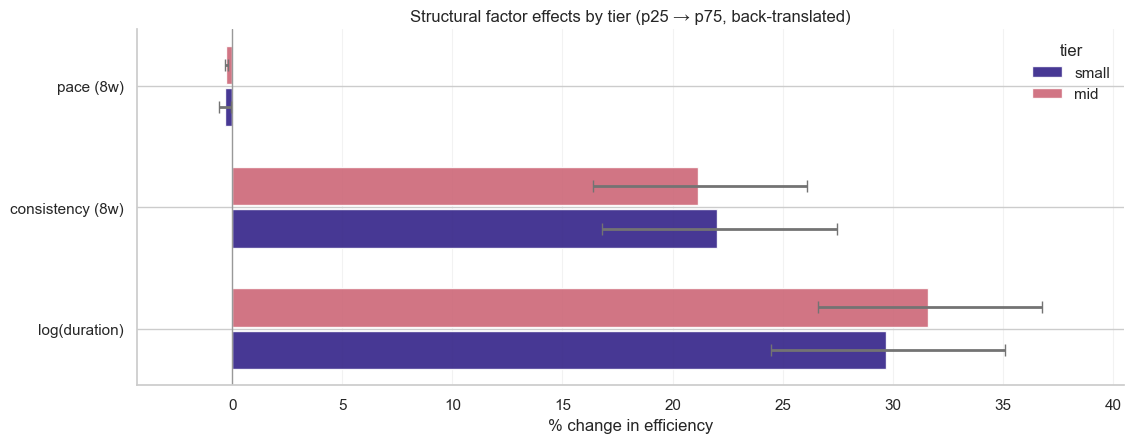

In [24]:
plot_effects_bars(effects_8, var_order=("log_duration", "cons8_median", "pace8_median"))

#### **2) WLS coefficients by tier (HC3)**  
This plot answers: *“What is the direction and strength of the association in the regression after controls?”*  
- Bars show $\hat\beta$ and whiskers show the 95% CI for each coefficient.
- Stars summarize statistical significance from the p-value (* $p<0.05$, ** $p<0.01$, *** $p<0.001$).
- Coefficients are on the $r_c$ scale, so they are less intuitive than the p25→p75 plot; that’s why we include both.

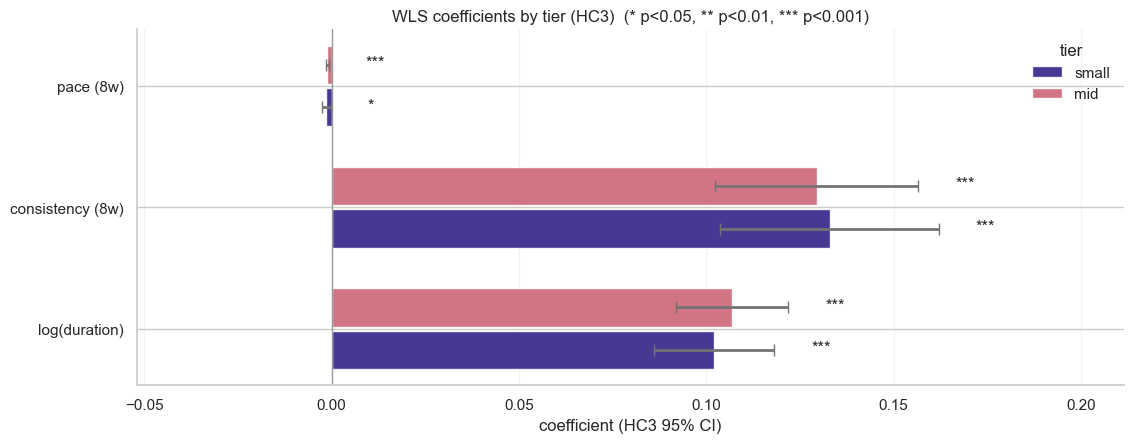

In [25]:
plot_coef_bars(coefs_8, var_order=("log_duration", "cons8_median", "pace8_median"))

**Conclusions from the output shown**
- **Log(duration)** has a large positive association with efficiency in both tiers and yields the largest p25 -> p75 uplift (with tight CIs).
- **Consistency** is also strongly positive in both tiers with large and statistically strong effects.
- **Pace** is close to zero (slightly negative) and much smaller than the other factors. Even if statistically significant, its practical impact is minor relative to duration and consistency.


Overall, the results are very similar across tiers: the point estimates are close and the 95% CIs overlap, so the evidence supports the interpretation that these structural factor relationships are effectively the same for small and mid channels rather than meaningfully different.

### Robustness across time windows (4w and 12w)

To check that our conclusions are not an artifact of the specific lookback window, we repeat the same within-tier WLS setup using structural factors computed over both a shorter horizon (4 weeks) and a longer horizon (12 weeks). For each window, we re-estimate the model separately for small and mid tiers and report (1) coefficient estimates with HC3 95% CIs and p-values, and (2) p25 → p75 effect sizes back-translated into % changes in efficiency.




In [26]:
models_4, effects_4, coefs_4 = run_spec_small_mid(
    small_df, mid_df,
    pace_col="pace4_median",
    cons_col="cons4_median",
    print_summary=False
)

models_12, effects_12, coefs_12 = run_spec_small_mid(
    small_df, mid_df,
    pace_col="pace12_median",
    cons_col="cons12_median",
    print_summary=False
)



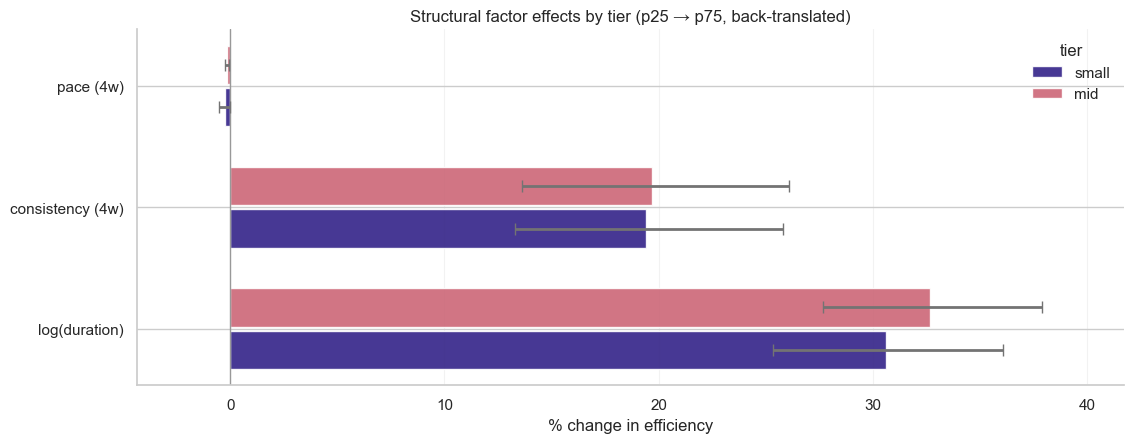

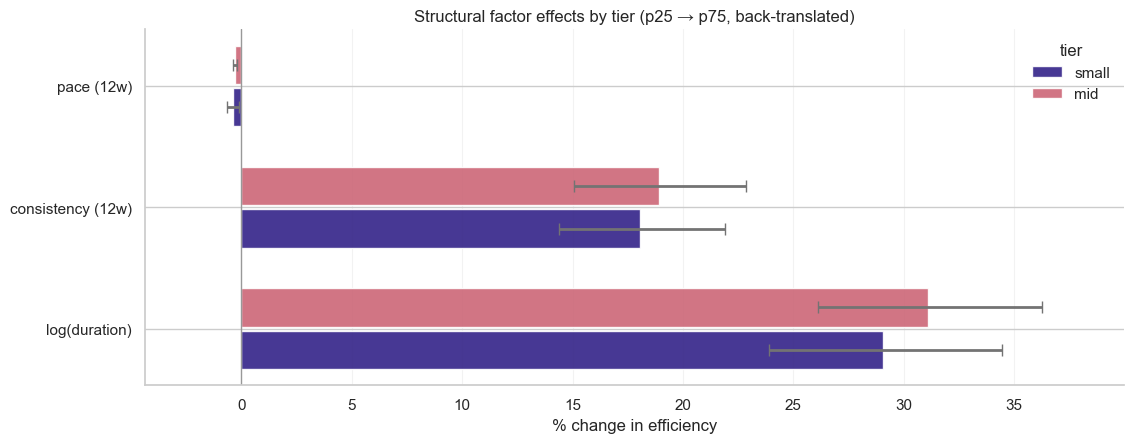

In [27]:
plot_effects_bars(effects_4, var_order=("log_duration", "cons4_median", "pace4_median"))
plot_effects_bars(effects_12, var_order=("log_duration", "cons12_median", "pace12_median"))

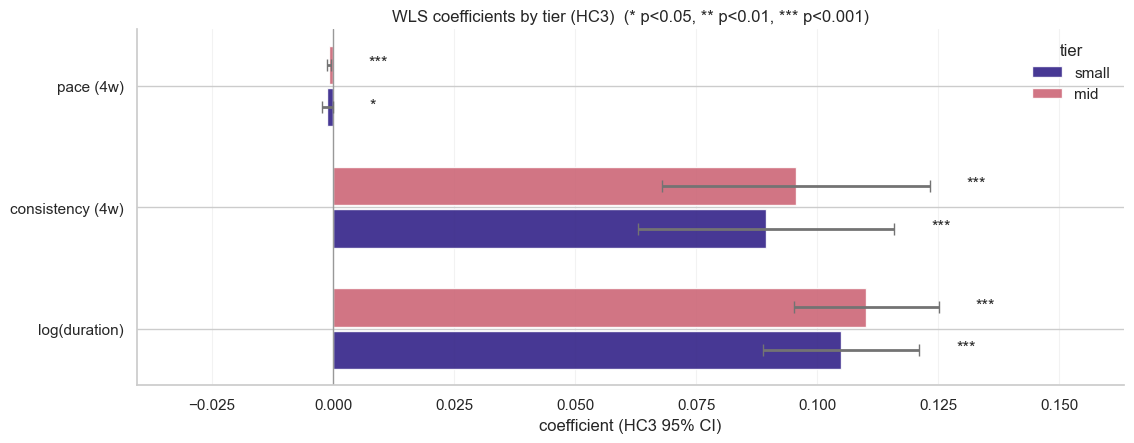

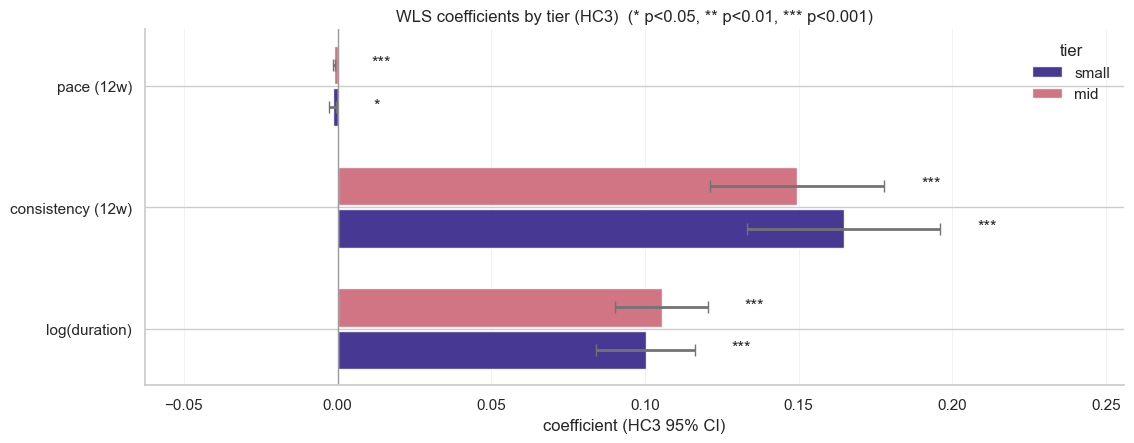

In [28]:
plot_coef_bars(coefs_4, var_order=("log_duration", "cons4_median", "pace4_median"))
plot_coef_bars(coefs_12, var_order=("log_duration", "cons12_median", "pace12_median"))

Across both 4w and 12w specifications, the qualitative pattern remains stable: duration and consistency show large positive associations with efficiency, while pace remains close to zero (slightly negative) and comparatively small in magnitude. The point estimates for small and mid are broadly similar within each window, and the uncertainty bands overlap substantially, suggesting that the relationship between structural factors and efficiency is consistent across tiers and robust to the choice of time window.

# 7 Growth Analysis - Research Question 4

### 7.1 Metric 1: Historical Mean Weekly Subscriber Gain

To determine if engagement efficiency translates into actual channel growth, we analyze the Mean Weekly Subscriber Gain.

Methodology:
1. Aggregation: We aggregate the `delta_subs` column from the `timeseries_df` by channel to compute the historical average weekly growth.
2. Integration: This metric is merged into the main `channel_df` (which contains the `is_outperformer` flag derived in RQ1).
3. Filtering: We filter the dataset to retain only the Small-to-Mid-Sized Cohort (subscribers < 100,000) to match the population studied in RQ1.
4. Comparison: We compare the growth rates of **Quiet Outperformers** vs. **Non-Outperformers**

### 7.2 Metric 1A: Unadjusted Descriptive Growth

Only considering channels with <100k subscribers!
Cohort Size (N): 94419
Outperformers (N): 2831
Non-Outperformers (N): 91588

--- Mann-Whitney U Test: mean_weekly_sub_gain ---
Hypothesis: Outperformer is greater than Non-Outperformer
Outperformer (Mean): 320.85
Non-Outperformer (Mean): 241.23
Statistic: 146077346.5, P-Value: 6.1426e-31
Result: Statistically Significant.


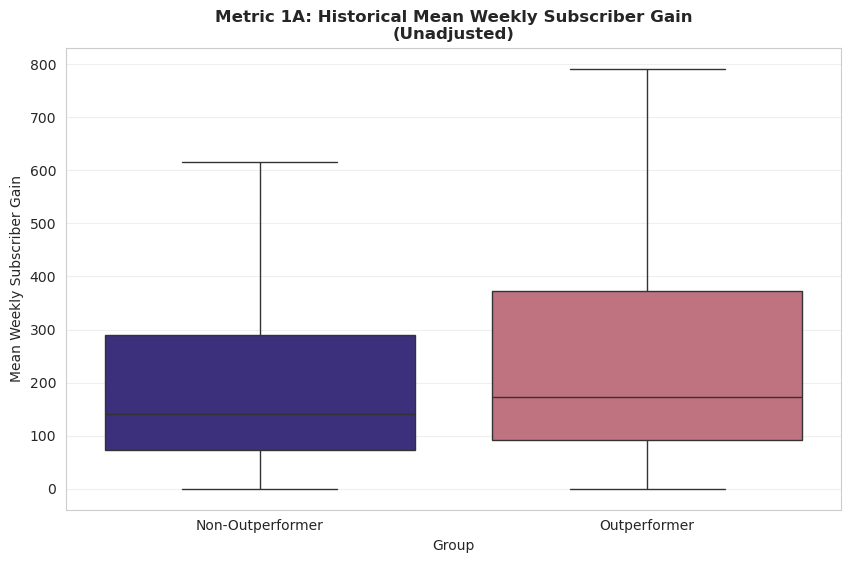

In [19]:
# Calculate Growth Metrics from Timeseries
growth_metrics = timeseries_df.groupby('channel')['delta_subs'].agg(
    mean_weekly_sub_gain='mean',
    std_weekly_sub_gain='std'
).reset_index()

# Merge & Filter Cohort
channel_df_rq4 = pd.merge(channel_df, growth_metrics, on='channel', how='left')
channel_df_rq4 = channel_df_rq4[channel_df_rq4['subscribers_cc'] < 100_000].copy()
channel_df_rq4['mean_weekly_sub_gain'] = channel_df_rq4['mean_weekly_sub_gain'].fillna(0)

# Statistics
outperformers_growth = channel_df_rq4[channel_df_rq4['is_outperformer']]
non_outperformers_growth = channel_df_rq4[~channel_df_rq4['is_outperformer']]

print("Only considering channels with <100k subscribers!")
print(f"Cohort Size (N): {len(channel_df_rq4)}")
print(f"Outperformers (N): {len(outperformers_growth)}")
print(f"Non-Outperformers (N): {len(non_outperformers_growth)}")

perform_mannwhitney_test(
    channel_df_rq4, 
    group_col='is_outperformer', 
    metric_col='mean_weekly_sub_gain', 
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Non-Outperformer'
)

# Visualization
plot_comparison_boxplot(
    data=channel_df_rq4,
    x_col='is_outperformer',
    y_col='mean_weekly_sub_gain',
    hue_col='is_outperformer',
    title='Metric 1A: Historical Mean Weekly Subscriber Gain\n(Unadjusted)',
    ylabel='Mean Weekly Subscriber Gain',
    xticklabels=['Non-Outperformer', 'Outperformer']
)

### 7.3 Propensity Score Matching (PSM)

To control for confounding factors (Channel Size, Age, Video Volume, and Category), we create a balanced "Control Group" of non-outperformers that look statistically identical to our "Quiet Outperformers."

Methodology:
1.  **Covariates:** We match on `log(subscribers)`, `log(channel_age)`, `log(video_count)`, and enforce an exact match on `category`.
2.  **Propensity Score:** We estimate the probability of being an outperformer using Logistic Regression.
3.  **Matching Strategy:**
    * **Exact Match:** We process each content category independently.
    * **Nearest Neighbor:** Within each category, we use a k-NN tree to find the single best control unit (nearest propensity score) for each treated unit.
    * **Caliper:** We enforce a strict caliper (0.01) to ensure quality matches.
    * **No Replacement:** Each control unit is used at most once.
4.  **Validation:** We check the Standardized Mean Difference (SMD) to ensure the groups are balanced ($|SMD| < 0.1$).

In [20]:
# Prepare Data for Propensity Score Matching
df_psm = channel_df_rq4.copy()

# Log-transform covariates
df_psm['log_subs'] = np.log10(df_psm['subscribers_cc'] + 1)
df_psm['log_age'] = np.log10(df_psm['channel_age_days'] + 1)
df_psm['log_videos'] = np.log10(df_psm['videos_cc'] + 1)

covariates = ['log_subs', 'log_age', 'log_videos']
exact_match_col = 'category_cc'

# Explicitly drop missing values before modeling
print(f"Original Cohort Size: {len(df_psm)}")
df_psm = df_psm.dropna(subset=covariates + [exact_match_col, 'is_outperformer'])
print(f"Size after dropping NaNs: {len(df_psm)}")

# Standardize Covariates
for col in covariates:
    df_psm[f'{col}_std'] = (df_psm[col] - df_psm[col].mean()) / df_psm[col].std()

# Pre-Matching Balance Check
print("\n--- Pre-Matching Balance (SMD) ---")
print("Target: |SMD| < 0.1")
for cov in covariates:
    smd = calculate_smd(df_psm, 'is_outperformer', f'{cov}_std')
    print(f"{cov}: {smd:.4f}")

# Estimate Propensity Scores and Perform Matching
formula = f"is_outperformer ~ {' + '.join([c + '_std' for c in covariates])} + C({exact_match_col})"
df_psm['propensity_score'] = estimate_propensity_scores(df_psm, formula)

# Perform Matching
treated_df = df_psm[df_psm['is_outperformer'] == True]
control_df = df_psm[df_psm['is_outperformer'] == False]

matched_ids = match_nearest_neighbor_within_category(
    treated_df,
    control_df,
    exact_match_col='category_cc',
    caliper=0.01
)
matched_df = df_psm.loc[list(matched_ids)].copy()

print(f"Matching Complete. Matched Total: {len(matched_df)}")
print(f"Matched Treated: {matched_df['is_outperformer'].sum()}")
print(f"Matched Control: {len(matched_df) - matched_df['is_outperformer'].sum()}")

# Validate Balance (Post-Matching)
print("\n--- Post-Matching Balance (SMD) ---")
for cov in covariates:
    print(f"{cov}: {calculate_smd(matched_df, 'is_outperformer', f'{cov}_std'):.4f}")

Original Cohort Size: 94419
Size after dropping NaNs: 94321

--- Pre-Matching Balance (SMD) ---
Target: |SMD| < 0.1
log_subs: -0.2046
log_age: -0.5140
log_videos: 0.1289

Fitting Propensity Score Model: is_outperformer ~ log_subs_std + log_age_std + log_videos_std + C(category_cc)
Starting matching (Treated=2830, Control=91491)...
Matching Complete. Matched Total: 5418
Matched Treated: 2709
Matched Control: 2709

--- Post-Matching Balance (SMD) ---
log_subs: 0.0314
log_age: -0.0058
log_videos: 0.0157


### 7.4 Metric 1B and 2: Matched Performance (Subscribers and Views)

--- Metric 1B: Subscriber Growth ---

--- Mann-Whitney U Test: mean_weekly_sub_gain ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 322.31
Control (Mean): 265.16
Statistic: 4026845.0, P-Value: 2.6457e-10
Result: Statistically Significant.

--- Metric 2: View Growth ---

--- Mann-Whitney U Test: mean_weekly_view_gain ---
Hypothesis: Outperformer is less than Control
Outperformer (Mean): 35922.35
Control (Mean): 62473.29
Statistic: 2618593.0, P-Value: 9.8824e-75
Result: Statistically Significant.

Interpretation: This confirms the 'Quiet' nature of Outperformers.
Despite higher subscriber growth (Metric 1B), they accumulate views significantly slower than the control group (Metric 2).
This suggests they prioritize efficiency and loyalty over viral reach.


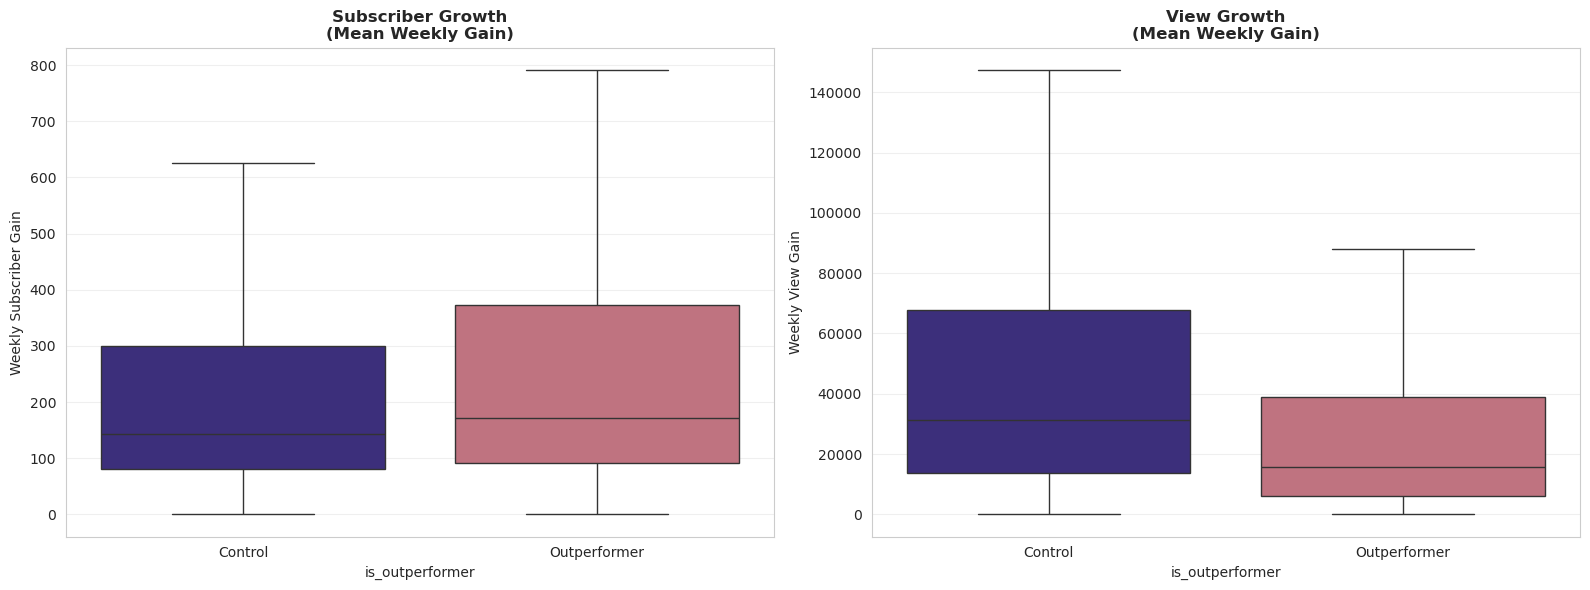

In [23]:
# Calculate View Growth Metrics from Timeseries
view_metrics = timeseries_df.groupby('channel')['delta_views'].agg(
    mean_weekly_view_gain='mean'
).reset_index()

# Merge view metrics into the matched cohort (Subscriber gain is already in 'mean_weekly_sub_gain')
matched_performance = pd.merge(matched_df, view_metrics, on='channel', how='left')
matched_performance['mean_weekly_view_gain'] = matched_performance['mean_weekly_view_gain'].fillna(0)

# Statistical Testing

print("--- Metric 1B: Subscriber Growth ---")
perform_mannwhitney_test(
    matched_performance, 
    group_col='is_outperformer', 
    metric_col='mean_weekly_sub_gain', 
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Control'
)

print("\n--- Metric 2: View Growth ---")
# Testing if Outperformers have LOWER view growth than Control
stat, p_value = perform_mannwhitney_test(
    df=matched_performance, 
    group_col='is_outperformer', 
    metric_col='mean_weekly_view_gain', 
    alternative='less', 
    group1_label='Outperformer',
    group2_label='Control'
)

if p_value < 0.05:
    print("\nInterpretation: This confirms the 'Quiet' nature of Outperformers.")
    print("Despite higher subscriber growth (Metric 1B), they accumulate views significantly slower than the control group (Metric 2).")
    print("This suggests they prioritize efficiency and loyalty over viral reach.")

# Visualization (Side-by-Side)
plot_dual_metric_boxplot(
    data=matched_performance,
    x_col='is_outperformer',
    metric1='mean_weekly_sub_gain',
    metric2='mean_weekly_view_gain',
    titles=['Subscriber Growth\n(Mean Weekly Gain)', 'View Growth\n(Mean Weekly Gain)'],
    ylabels=['Weekly Subscriber Gain', 'Weekly View Gain'],
    xticklabels=['Control', 'Outperformer']
)

### 7.5 Metric 3 - Stability & Activity Context (Metrics 3A & 3B)

**Interim Summary: The "Loyal Niche" Hypothesis**

Our analysis so far has revealed a distinct behavioral profile for Quiet Outperformers:
1.  **Metric 1 (Subscribers):** Outperformers grow their audience **significantly faster** than comparable control channels ($P_{value} \approx 0$).
2.  **Metric 2 (Views):** Surprisingly, Outperformers accumulate views **significantly slower** than control channels ($P_{value} \approx 0$).

**Interpretation:**
This divergence - High Subscriber Growth coupled with Low View Growth — suggests that Quiet Outperformers are not "Viral" channels chasing algorithmic hits (which generate massive views but fewer loyal subs). Instead, they appear to be **"Community Builders."** They attract viewers who are highly likely to convert into subscribers, even if their total view reach is smaller.

**Metric 3 Motivation:**
To validate this "Community Builder" hypothesis, we must understand their posting behavior. Do they achieve this growth through constant daily uploads, or through a more selective strategy? We introduce two new dimensions:
* **Metric 3A (Stagnation Rate):** This calculates the percentage of weeks where the channel had no subscriber growth. A high percentage suggests that growth happens in sudden spikes driven by new video uploads, rather than through a steady stream of traffic from the YouTube algorithm.
* **Metric 3B (Posting Frequency):** The average number of weekly uploads. This helps determine if stagnation is a result of audience disinterest or a lack of new content.

Calculating stagnation rates and activity metrics...
Analysis N: 5302 channels

--- Metric 3A: Stagnation Rate ---

--- Mann-Whitney U Test: stagnation_rate_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 0.17
Control (Mean): 0.10
Statistic: 4517553.0, P-Value: 8.1129e-73
Result: Statistically Significant.

--- Metric 3B: Posting Frequency ---
Median Uploads (Outperformer): 1.38
Median Uploads (Control):      0.98

--- Mann-Whitney U Test: mean_weekly_uploads ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 2.28
Control (Mean): 2.61
Statistic: 3913912.5, P-Value: 3.5284e-13
Result: Statistically Significant.


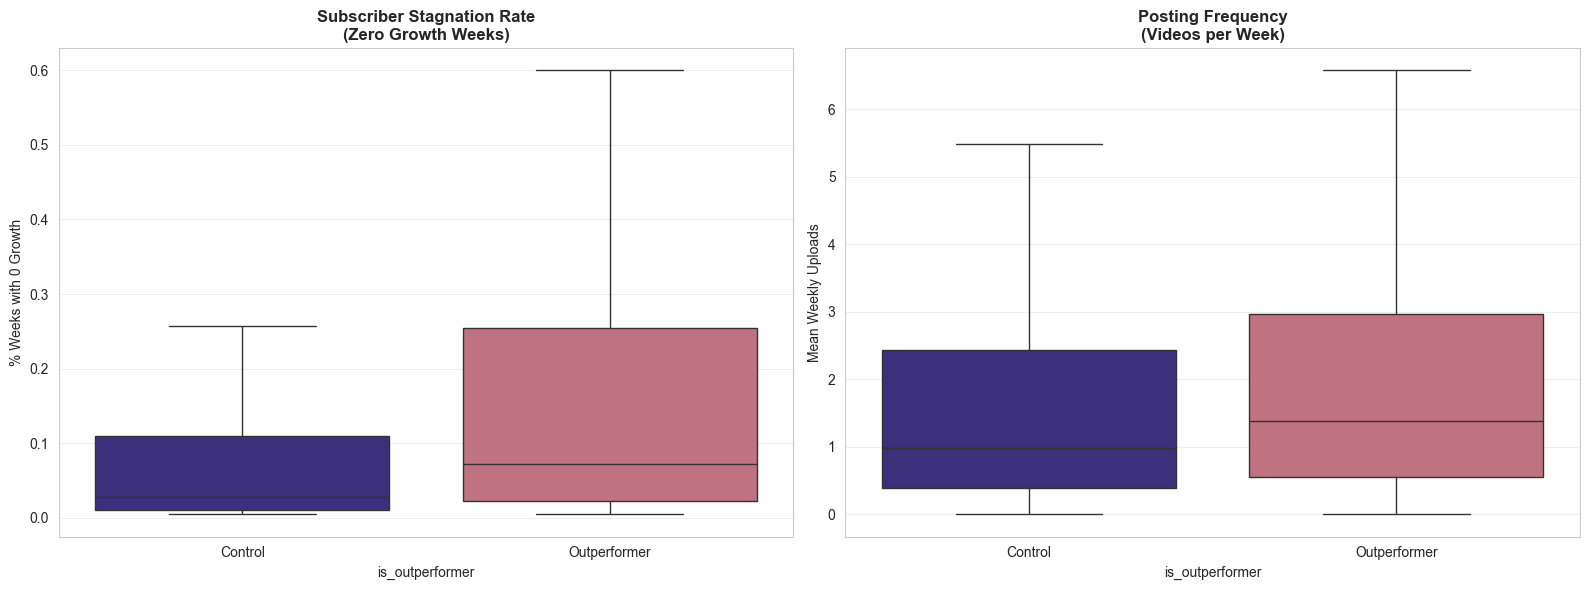

In [14]:
# Calculate Metrics from Raw Timeseries
# We must use timeseries_df because we need the weekly history, not just the average.
# First, filter timeseries to only the channels in our matched cohort.
matched_ids = matched_df['channel'].unique()
cohort_ts = timeseries_df[timeseries_df['channel'].isin(matched_ids)]

print("Calculating stagnation rates and activity metrics...")
activity_metrics = cohort_ts.groupby('channel').agg(
    stagnation_rate_subs=('delta_subs', calculate_stagnation_rate),
    mean_weekly_uploads=('delta_videos', 'mean')
).reset_index()

# Merge into Matched DataFrame
df_stability = pd.merge(matched_df, activity_metrics, on='channel', how='left')

# Data Cleaning
# Drop rows where metrics could not be computed (e.g. no history)
df_stability_clean = df_stability.dropna(subset=['stagnation_rate_subs', 'mean_weekly_uploads'])
print(f"Analysis N: {len(df_stability_clean)} channels")

# Statistical Testing

# Metric 3A: Stagnation Rate
# Hypothesis: Outperformers have MORE stagnation (bursty growth) -> 'greater'
print("\n--- Metric 3A: Stagnation Rate ---")
perform_mannwhitney_test(
    df=df_stability_clean,
    group_col='is_outperformer',
    metric_col='stagnation_rate_subs',
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Control'
)

# Metric 3B: Posting Frequency
# Hypothesis: Outperformers post MORE frequently (median) -> 'greater'
print("\n--- Metric 3B: Posting Frequency ---")
group_out = df_stability_clean[df_stability_clean['is_outperformer'] == 1]['mean_weekly_uploads']
group_ctrl = df_stability_clean[df_stability_clean['is_outperformer'] == 0]['mean_weekly_uploads']
print(f"Median Uploads (Outperformer): {group_out.median():.2f}")
print(f"Median Uploads (Control):      {group_ctrl.median():.2f}")

perform_mannwhitney_test(
    df=df_stability_clean,
    group_col='is_outperformer',
    metric_col='mean_weekly_uploads',
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Control'
)

# 5. Visualization (Side-by-Side)
plot_dual_metric_boxplot(
    data=df_stability_clean,
    x_col='is_outperformer',
    metric1='stagnation_rate_subs',
    metric2='mean_weekly_uploads',
    titles=['Subscriber Stagnation Rate\n(Zero Growth Weeks)', 'Posting Frequency\n(Videos per Week)'],
    ylabels=['% Weeks with 0 Growth', 'Mean Weekly Uploads'],
    xticklabels=['Control', 'Outperformer']
)

### 7.6 Metric 4: Long-Term Cumulative Growth Trajectory

To validate the hypothesis that high engagement efficiency leads to compounding growth, we analyze the **Median Cumulative Subscriber Gain** over a 3-year period.

**Methodology:**
1.  **Relative Time Alignment:** We align all channels to Week 0 (the start of their tracking period) to compare growth *speed* rather than calendar age.
2.  **Matched Cohort:** We use the PSM-matched "twins" (identical age, size, and category at start) to ensure a fair comparison.
3.  **Metric:** We calculate the cumulative sum of subscribers gained for every week and compare the Median trajectory of Outperformers vs. Control.


--- Statistical Checkpoints (cum_subs) ---

Checkpoint: Week 52

--- Mann-Whitney U Test: cum_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 10283.55
Control (Mean): 8769.25
Statistic: 2495818.0, P-Value: 4.7135e-01
Result: Not Statistically Significant.

Checkpoint: Week 104

--- Mann-Whitney U Test: cum_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 17488.29
Control (Mean): 15696.61
Statistic: 1537275.0, P-Value: 1.1208e-01
Result: Not Statistically Significant.

Checkpoint: Week 160

--- Mann-Whitney U Test: cum_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 21672.87
Control (Mean): 20194.48
Statistic: 555338.0, P-Value: 4.2650e-02
Result: Statistically Significant.


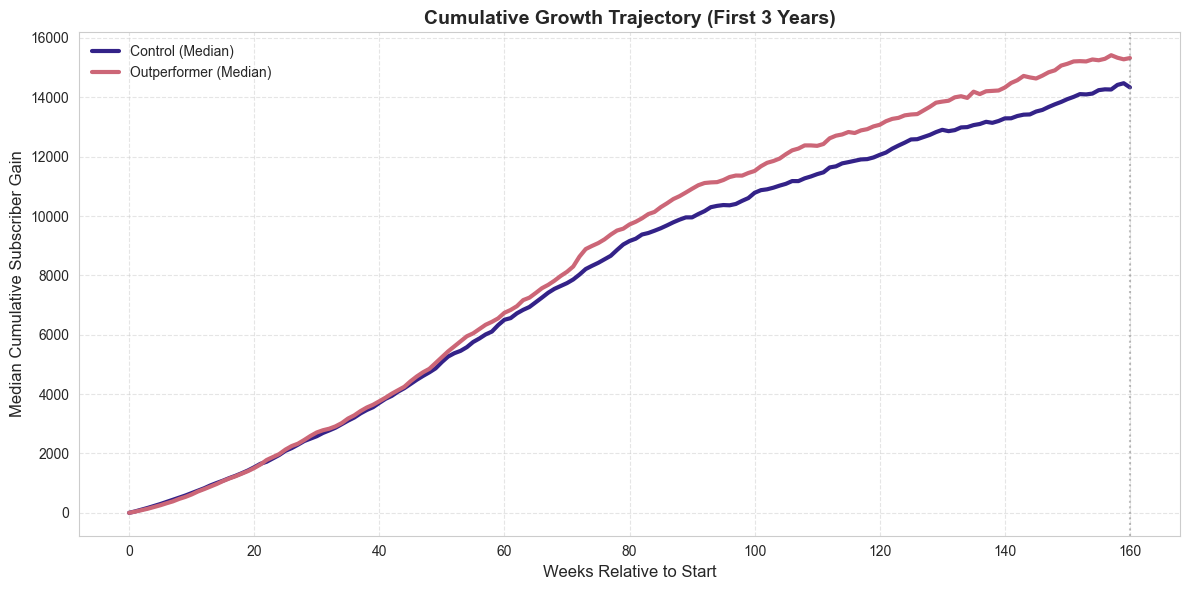

In [15]:
# Prepare Data
matched_ids = matched_df['channel'].unique()
ts_matched = timeseries_df[timeseries_df['channel'].isin(matched_ids)].copy()
channel_map = matched_df.set_index('channel')['is_outperformer'].to_dict()
ts_matched['is_outperformer'] = ts_matched['channel'].map(channel_map)

# Align Time & Calculate Cumulative Growth
ts_matched = ts_matched.sort_values(['channel', 'datetime'])
ts_matched['week_num'] = ts_matched.groupby('channel').cumcount()
ts_matched['cum_subs'] = ts_matched.groupby('channel')['delta_subs'].cumsum()

# Statistical Checkpoints
check_growth_milestones(
    df=ts_matched, 
    milestones=[52, 104, 160], # Year 1, Year 2, Year 3
    metric_col='cum_subs'
)

# Aggregate Trajectories (Median)
trajectory_df = ts_matched.groupby(['is_outperformer', 'week_num'])['cum_subs'].median().reset_index()

# Week 160 (approx 3 years)
trajectory_df = trajectory_df[trajectory_df['week_num'] <= 160]

# Visualization
plot_growth_trajectory(
    trajectory_df=trajectory_df,
    x_col='week_num',
    y_col='cum_subs',
    hue_col='is_outperformer',
    title="Cumulative Growth Trajectory (First 3 Years)",
    xlabel="Weeks Relative to Start",
    ylabel="Median Cumulative Subscriber Gain"
)

### 7.7 Final Conclusion: The Anatomy of a "Quiet Outperformer"

**Synthesis of Findings:**

* **The "Quiet" Nature (Metrics 2 & 3A):**
    * **Lower Viral Reach:** Unlike typical successful channels that chase massive view counts, Quiet Outperformers actually gain **significantly fewer views** per week (Metric 2). They do not rely on "viral hits" or algorithmic jackpots.
    * **Bursty Growth:** They experience more "quiet" weeks (Metric 3A: Higher Stagnation Rate) where they see zero growth. This implies they are not riding a constant wave of algorithmic recommendations (which would provide a steady trickle of views and subscribers). Instead, their growth is likely tied directly to their specific content releases.

* **The "Outperformance" (Metric 1):**
    * **High Conversion:** Despite getting fewer views, they achieve **significantly higher subscriber growth** (Metric 1). This is the "Outperformer" magic: their **Engagement Efficiency** (likes/comments per view) is so high that a single view is far more likely to convert into a subscriber than it is for a control channel. They build **Loyalty**, not just Reach.

* **The Strategy: "Consistent Quality" (Metric 3B):**
    * **Active, Not Spammy:** The Control group is distorted by "spammers" - channels that upload dozens of videos a week to fish for views (high mean uploads, low median).
    * **Reliable Creators:** By contrast, the **typical (median) Outperformer** posts *more frequently* (1.38 videos/week) than the typical Control channel (0.98 videos/week). They are disciplined creators who stick to a schedule, avoiding both "spam" and "abandonment."

* **Long-Term Growth (Metric 4):**

    * **No Head Start**: Statistical tests confirm no significant difference in growth for the first two years (Weeks 52 & 104), proving that Outperformers do not possess an inherent advantage.
    * **Compounding Payoff**: The strategy is a long-term investment. A statistically significant lead ($p < 0.05$) only emerges by Week 160 (Year 3), confirming that the compounding value of a loyal community takes time to break away from the volatility of viral chasing.

**Summary Statement:**
> *"Quiet Outperformers are **Community Builders**. They reject the 'viral lottery' strategy of chasing massive view counts. Instead, they maintain a disciplined, higher-than-average posting schedule of high-efficiency content. While this approach leads to more periods of 'stagnation' (fewer passive/algorithmic views), it generates significantly higher long-term subscriber growth by converting viewers into loyal fans at an exceptional rate."*

## 5. Mathematical model of Research Questions

This section presents the detailed methods proposed for each research question.

### RQ2: Are quiet outperformers concentrated in particular content categories, or do their engagement efficiency patterns vary across categories?

---

#### 1. Choice of Content Categorization

We consider two approaches to define a channel's content category: (a) Using YouTube's 15 official categories, (b) Using data-driven clusters
To better capture real content communities, we construct data-driven clusters from video-level textual data (tags).

This approach is feasible in our setting with the new lightweight dataset (tags_processed.parquet) containing only channel_id, display_id, tags, and upload_date (reducing the original metadata file from 13 GB to 5 GB). Also instead of loading the entire dataset at once, we can iterate through it in manageable chunks using the iterate_parquet_stream function we built in the data loader.

#### 2. Building Data-Driven Content Clusters

##### 2.1 Text Preprocessing
For each video:
1. Clean tags text:
   - lowercase
   - remove punctuation, stopwords, and numbers
   - lemmatize or stem words
2. Join all tags into one document string per video.


##### 2.2 Text Representation
We represent each video's tags as a mixture of latent topics using **Latent Dirichlet Allocation (LDA)**, a probabilistic topic modeling approach.

We considered to use transformer embeddings (e.g., Sentence-BERT) and density-based clustering (HDBSCAN), which captures semantic similarity more effectively than LDA but is computationally expensive for millions of short tag strings and sensitive to parameter tuning. So we decided to use LDA.


LDA assumes that:
- each video's tag set is generated from a mixture of *K* latent topics, and
- each topic is a probability distribution over words.

Formally, for each video *v* (treated as a “document” of tags):

$$
\theta_v \sim \text{Dirichlet}(\alpha), \quad \phi_k \sim \text{Dirichlet}(\beta)
$$

where
- $\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK})$ represents the topic proportions for video *v*,
- $\phi_k$ is the word distribution for topic *k*,
- $\alpha$ and $\beta$ are Dirichlet hyperparameters controlling sparsity.

Each tag $w_{vn}$ in video *v* is generated by:
$$
z_{vn} \sim \text{Multinomial}(\theta_v), \quad w_{vn} \sim \text{Multinomial}(\phi_{z_{vn}})
$$

After fitting the model, each video is represented by its topic distribution vector:

$$
\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK}), \quad \sum_{k=1}^{K} \theta_{vk} = 1
$$

We determine the optimal number of topics *K* using **topic coherence** and **perplexity** metrics.
- Higher coherence indicates more interpretable and distinct topics.
- Lower perplexity indicates better generalization to unseen data.

Each topic is then characterized by its most probable words, and then summarized using a large language model (LLM) for interpretability.

Once trained, we assign each video to its dominant topic:
$$
\text{Topic}(v) = \arg\max_k \theta_{vk}
$$

These inferred topics form data-driven content categories, which are later aggregated to the channel level (next step).

#### 3. Aggregating Clusters to the Channel Level

Because quiet outperformers are defined at the channel level, we aggregate the video clusters as follows:

1. Count the number of videos per cluster for each channel:

    $$
    n_{c,k} = \mathrm{\#\ of\ videos\ from\ channel\ } c \mathrm{\ in\ cluster\ } k
    $$

2. Compute each channel's cluster proportion:

    $$
    p_{c,k} = \frac{n_{c,k}}{\sum_{j} n_{c,j}}
    $$

3. Assign the dominant cluster:

    $$
    \text{Cluster}_c = \arg\max_k p_{c,k}
    $$

4. Compute topic diversity using Shannon entropy:

    $$
    H_c = -\sum_k p_{c,k} \log(p_{c,k})
    $$

    Channels with high entropy (e.g., $H_c > 1.5$) can be excluded to focus on thematically consistent creators.

#### 4. Comparing Engagement Efficiency Among Quiet Outperformers Across Categories

Let $\hat{\varepsilon}_c$ denote the *residual efficiency* for channel $c$, derived from RQ1, and let $k$ denote its assigned content category or cluster (from YouTube's predefined categories or LDA-derived topics).

##### 4.1 Summary Statistics and Visualization

For each category $k$, compute descriptive statistics among quiet outperformers:
$$
\text{Mean}_k = \frac{1}{n_k} \sum_{c \in k} \hat{\varepsilon}_c, \quad
\text{Median}_k, \quad \text{IQR}_k, \quad \text{SD}_k
$$

Visualize the efficiency distributions across categories using violin plots, boxplots**, or kernel density plots (KDE).
These visuals reveal whether outperformers from certain content types (e.g., Education, Gaming, Lifestyle) tend to achieve systematically higher engagement efficiency.

##### 4.2 Testing Differences in Efficiency Distributions

To formally test whether efficiency distributions differ across categories, apply the Kruskal-Wallis H test:

$$
H_0: f_1(\hat{\varepsilon}) = f_2(\hat{\varepsilon}) = \dots = f_K(\hat{\varepsilon})
$$

$$
H = \frac{12}{N(N+1)} \sum_{k=1}^{K} n_k (\bar{R}_k - \bar{R})^2
$$

where:
- $n_k$ = number of outperformers in category $k$
- $\bar{R}_k$ = mean rank of efficiency in category $k$
- $\bar{R}$ = mean rank overall
- $N$ = total number of outperformers

If $p < 0.05$, we reject $H_0$ and conclude that at least one content category of outperformers exhibits a distinct engagement efficiency distribution.

If the global test is significant, perform Dunn's post-hoc tests with False Discovery Rate correction to identify which categories differ.


##### 4.3 Concentration of Outperformers Across Categories

To assess whether quiet outperformers are disproportionately represented in certain content types, compare the observed vs. expected counts of outperformers per category using a **Chi-square goodness-of-fit test**:

$$
\chi^2 = \sum_{k=1}^{K} \frac{(O_k - E_k)^2}{E_k}
$$

where:
- $O_k$ = observed number of outperformers in category $k$
- $E_k$ = expected number based on overall category proportions in the full dataset

A significant result ($p < 0.05$) indicates that outperformers are concentrated in specific content categories rather than evenly distributed.



### RQ3: Which structural choices (video duration, posting frequency, posting consistency) are statistically associated with higher efficiency within each size tier?

---




We analyze how structural choices relate to engagement efficiency while removing scale effects and comparing channels within size tiers. Because efficiency co-varies with subscriber count and channels differ by composition, naive comparisons are biased. We address this by (i) residualizing efficiency against size in a log–log baseline, and (ii) estimating within-tier regressions.

#### 1. Outcome Metric: Size-Adjusted Efficiency (Residual)

From the channel efficiency we computed before,

Baseline (size) model:
$$
\log_{10}(E_c) \;=\; a + b\,\log_{10}(\text{subscribers}_c) + \varepsilon_c.
$$

Residual (outcome):
$$
r_c \;=\; \log_{10}(E_c) - \big(a + b\,\log_{10}(\text{subscribers}_c)\big).
$$
Here, $r_c>0$ indicates performance above size-based expectation.

#### 2. Size Tiers

Tiers are defined by subscriber quantiles:
- Small: 0–50th percentile
- Mid: 50–90th percentile

Analyses are run separately within each tier.


#### 3. Structural Predictors (8-week window)

All predictors are backward-looking (no leakage) and summarized at the channel level:

- Posting frequency (pace): median weekly uploads over the prior 8 weeks.
- Posting consistency (0–1):
$$
\text{cons8} \;=\; \mathrm{clip}\!\left(1-\frac{\mathrm{std}_8}{\max(\mathrm{mean}_8,\varepsilon)},\,0,\,1\right),\quad \varepsilon=0.1.
$$
- Video duration: channel median duration; modeled as $\log(\text{duration})$ to reduce skew.

Predictors are z-scored within tier to make coefficients comparable.

#### 4. Estimation and Final Tests

Within each tier, we estimate a **weighted least squares** regression:
$$
r_c \;=\; \beta_0 + \beta_1\,\text{pace8}_c + \beta_2\,\text{cons8}_c + \beta_3\,\log(\text{duration}_c) \, + \, \text{controls (category FE, log age, videos/day, ... )} \, + \, \varepsilon_c.
$$

- Weights: number of videos for the channel (precision weighting of $r_c$).
- Standard errors: HC3 (heteroskedasticity-robust with a leverage adjustment).
- Final tests: two-sided tests of $H_0:\beta_k=0$ for pace, consistency, and duration in each tier.
- Effect sizes: report predicted change in $r_c$ from 25th→75th percentile for each factor with 95% CIs; translate to % on the original scale for readability.

#### 5. Robustness

- Recompute predictors with 4w and 12w windows.
- Duration variants: trimmed mean
- Check pace–consistency collinearity; confirm stability.


**Interpretation.** A positive and significant $\beta_2$ indicates that more consistent posting is associated with higher size-adjusted efficiency within that tier; $\beta_1$ captures frequency beyond consistency; $\beta_3$ summarizes how typical (log) duration relates to efficiency after basic controls.


### RQ4: Do channels that currently exhibit exceptional engagement also show historically stronger or more stable growth patterns?

---

To answer this question, we compare the long-term growth dynamics of two groups: "Outperformers" (treated) and "non-Outperformers" (control). Unlike event-based analyses where treatment occurs at a specific time, our treatment is status-based: channels are classified as outperformers according to their engagement efficiency. Because outperformers are not randomly assigned and tend to differ in characteristics such as size, age, and category, a simple comparison would be biased. This selection bias introduces confounding, which we address using a quasi-causal inference framework based on Propensity Score Matching (PSM).

By doing this, we aim to isolate the effect of "engagement efficiency" on three dimensions of growth: **Magnitude** (Gain), **Consistency** (Stagnation), and **Activity** (Posting Frequency).


#### 1. Causal Methodology: Propensity Score Matching (PSM)

The methodology relies on the propensity score, $e(X)$, which is the conditional probability of a channel being in the treated group (Outperformer) given its pre-treatment covariates $X$:

$$
e(X) = P(\text{is\_outperformer} = 1 \mid X)
$$

We estimate the propensity score $e(X)$ using a **Logistic Regression** model.

The model predicts the treatment (`is_outperformer`) based on a set of key confounding variables:

$$\text{logit}(e(X)) = \beta_0 + \beta_1 \cdot \log_{10}(\text{subscribers\_cc} + 1) + \beta_2 \cdot \log_{10}(\text{channel\_age\_days} + 1) + \beta_3 \cdot \log_{10}(\text{videos\_cc} + 1) + C(\text{category\_cc})
$$

* **Logarithmic Transformation**: Covariates such as `subscribers_cc`, `channel_age_days`, and `videos_cc` are heavily right-skewed. We apply a shifted $\log_{10}$ transformation to these features. This compresses the scale, mitigates the influence of extreme outliers, and better approximates the linear relationship assumed by the logistic regression's logit link function.

After estimating propensity scores for all channels, we perform 1:1 nearest-neighbor matching to create a balanced dataset.

* **Exact Matching**: We enforce exact matching on the `category_cc` variable. This ensures that a treated "Gaming" channel is only ever matched with a control "Gaming" channel, eliminating bias from content category differences.

* **Caliper Matching**: We impose a small caliper (e.g., $0.01$). This means a match is only considered valid if the absolute difference in propensity scores between the treated and control unit is less than this caliper value, ensuring only highly similar channels are paired.

To verify the success of the matching process, we assess covariate balance using the **Standardized Mean Difference (SMD)**. The SMD measures the difference in means between the treated and control groups in units of pooled standard deviation:

$$
\text{SMD} = \frac{\bar{X}_{\text{Treated}} - \bar{X}_{\text{Control}}}{\sqrt{\frac{S_{\text{Treated}}^2 + S_{\text{Control}}^2}{2}}}
$$

SMD is a critical diagnostic. Before matching, a large SMD ($|\text{SMD}| > 0.1$) indicates imbalance and justifies the need for matching. After matching, we require $|\text{SMD}| < 0.1$ for all covariates to confirm that the groups are statistically comparable and selection bias has been minimized.


#### 2. Growth & Activity Metrics

For a channel $c$ with a time-series of $T$ weeks, let $S_t$ be the total subscribers, $V_t$ be the cumulative views, and $U_t$ be the number of video uploads at week $t$. The weekly deltas are $\Delta S_t$, $\Delta V_t$, and $\Delta U_t$.

**Metric 1 & 2: Historical Mean Weekly Gain (Magnitude)**
To measure pure growth magnitude, we calculate the arithmetic mean of weekly gains for subscribers (Metric 1) and views (Metric 2).
$$
\mu_{\Delta} = \frac{1}{T} \sum_{t=1}^{T} \Delta S_t
$$

(Note: For Metric 2, $\Delta S_t$ is replaced by $\Delta V_t$).

**Metric 3A: Stagnation Rate (Consistency)**
We define "Stagnation" as the proportion of weeks where a channel fails to grow (gains zero or loses subscribers). Let $\mathbb{I}(\cdot)$ be the indicator function:
$$
\text{Stagnation Rate} = \frac{1}{T} \sum_{t=1}^{T} \mathbb{I}(\Delta S_t \leq 0)
$$

**Metric 3B: Posting Frequency (Activity)**
To measure channel activity, we calculate the mean weekly uploads:
$$
\mu_{\text{uploads}} = \frac{1}{T} \sum_{t=1}^{T} \Delta U_t
$$

##### 3. Statistical Inference: Mann-Whitney U Test

Youtube growth metrics follow power-law distributions and are rarely normally distributed. Consequently, parametric tests (like the t-test) are inappropriate.

We utilize the **Mann-Whitney U Test**, a non-parametric rank-sum test.

* **Null Hypothesis ($H_0$):** The distribution of growth metric $M$ is identical for Outperformers and Control.
* **Alternative Hypothesis ($H_1$):** The median of $M$ for Outperformers is strictly greater (or smaller) than the Control.

This allows us to determine statistical significance without assuming data normality.

